# PROG8431 – Data Analysis, Mathematics, Modeling and Algorithms

## Problem Analysis Workshop C – Transformation / Linear Regression

**Group 5**

| Team member | Student ID |
|:--|--:|
| Asangika Hettiarachchi | 7461502 |
| Juan Antonio Sainz Galvez | 9072844 |
| Ved Vishal Patel | 9111628 |

### Research Question

To what extent do property location and community characteristics influence residential listing prices across Ontario?

# B. Setup and configuration 



In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import boxcox, ks_2samp, chi2_contingency, shapiro
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from sklearn.neighbors import BallTree
import statsmodels.api as sm
import statsmodels.formula.api as smf

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
pd.set_option("display.max_columns", 60)
RANDOM_STATE = 6174          # same seed used in the class demonstration
DATA_DIR = Path("data")      # relative path: never use C:\...

### Section B – Setup and Configuration

This section imports the required Python libraries for data manipulation, visualization, statistical analysis and regression modelling. It also configures Pandas display settings, suppresses unnecessary warnings, defines a consistent random state for reproducibility and sets the data directory path.

<!-- PART 0 – OWNER: Antonio -->
# C. Data sources, cleaning and integration (Antonio)

Our term-project dataset only has five fields per listing (address, area name, price, latitude, longitude).
To reach **at least 25 usable variables** we combine it with two public sources and derive location features.

| # | Source | What it adds | File |
|:-:|:--|:--|:--|
| 1 | Kaggle – *Ontario Residential Property Data* (mnabaee/ontarioproperties) | Listing price, address, area name, latitude and longitude (25,351 listings) | `data/properties.csv` |
| 2 | Statistics Canada – *Census Profile 2021*, census subdivisions (municipalities), Census Profile SDMX API (`api.statcan.gc.ca`) | 31 municipal indicators: population, density, age, dwelling types, incomes, low income, owners/renters, shelter costs, dwelling value, rent, immigration, education, labour force, commuting | `data/census_2021_csd_ontario.csv` |
| 3 | Wikidata – property P571 (*inception*) for each Ontario census subdivision, plus six manually added municipal incorporation dates (marked in `date_source`) | A real calendar date per municipality (used for the Julian date section) | `data/municipality_inception_dates.csv` |
| 4 | Derived from coordinates and address | Distance to downtown Toronto and to downtown Kitchener (haversine, km), condo/unit flag, region, city size class | computed below |

**Rationale.** A listing price depends on the property *and* on the community around it. Census indicators describe that
community (income, density, housing stock, commuting), and the distances capture the pull of the Toronto and
Kitchener-Waterloo job markets – the comparison our term project is about.

**How the join works.** Each address ends with its municipality (e.g. `"... Waterloo, ON"`). We match the end of the
address to a Statistics Canada census-subdivision name (longest match wins). About 11% of addresses use a former
municipality or community name (e.g. Kanata, Orleans, Ancaster); those listings take the municipality of their
nearest matched neighbour by latitude/longitude. `scripts/fetch_external_data.py` shows how sources 2 and 3 were downloaded.

In [2]:
TORONTO_DOWNTOWN = (43.6532, -79.3832)
KITCHENER_DOWNTOWN = (43.4516, -80.4925)
ONTARIO_LAT_RANGE = (41.6, 56.9)
ONTARIO_LNG_RANGE = (-95.2, -74.3)
MIN_VALID_PRICE = 10_000


def load_properties(path):
    """Read the Kaggle listings file and give the columns clear snake_case names."""
    listings = pd.read_csv(path, index_col=0)
    return listings.rename(columns={"Address": "address", "AreaName": "area_name",
                                    "Price ($)": "price", "lat": "lat", "lng": "lng"})


def clean_properties(listings):
    """Apply the Group 5 cleaning rules and report how many rows each rule removes."""
    rules = {
        "missing coordinates (-999)": (listings["lat"] != -999) & (listings["lng"] != -999),
        "coordinates outside Ontario": listings["lat"].between(*ONTARIO_LAT_RANGE)
                                       & listings["lng"].between(*ONTARIO_LNG_RANGE),
        f"price under ${MIN_VALID_PRICE:,}": listings["price"] >= MIN_VALID_PRICE,
    }
    keep = pd.Series(True, index=listings.index)
    for rule_name, rule_mask in rules.items():
        removed = (keep & ~rule_mask).sum()
        print(f"Removed {removed:>5,} rows: {rule_name}")
        keep &= rule_mask
    cleaned = listings[keep].copy()
    print(f"Rows kept: {len(cleaned):,} of {len(listings):,}")
    return cleaned


def haversine_km(lat, lng, point):
    """Great-circle distance in km from each (lat, lng) to a fixed (lat, lng) point."""
    lat1, lng1 = np.radians(lat), np.radians(lng)
    lat2, lng2 = np.radians(point[0]), np.radians(point[1])
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lng2 - lng1) / 2) ** 2
    return 6371.0 * 2 * np.arcsin(np.sqrt(a))


def build_name_lookup(census):
    """Map lower-case municipality names (and their English part before ' / ') to census codes."""
    lookup = {}
    for code_value, name in zip(census["csd_code"], census["csd_name"]):
        for variant in {name, name.split(" / ")[0]}:
            lookup.setdefault(variant.lower(), []).append(code_value)
    return lookup


def match_municipality(address, lookup, population):
    """Return the census code whose name matches the end of the address (longest match, largest population)."""
    words = address.replace(", ON", "").replace(",ON", "").split()
    for size in range(min(5, len(words)), 0, -1):
        candidate = " ".join(words[-size:]).lower()
        if candidate in lookup:
            return max(lookup[candidate], key=lambda c: population.get(c, 0))
    return np.nan


def fill_by_nearest_neighbour(listings, column):
    """Give unmatched listings the value of their nearest matched listing (haversine on lat/lng)."""
    matched = listings[listings[column].notna()]
    unmatched = listings[listings[column].isna()]
    tree = BallTree(np.radians(matched[["lat", "lng"]].values), metric="haversine")
    _, nearest = tree.query(np.radians(unmatched[["lat", "lng"]].values), k=1)
    listings.loc[unmatched.index, column] = matched[column].values[nearest[:, 0]]
    return listings


def assign_region(division_code):
    """Group Statistics Canada census divisions into eight Ontario regions (snake_case labels for clean dummy names)."""
    if division_code == 3520:
        return "toronto"
    if division_code in (3518, 3519, 3521, 3524):
        return "gta_excl_toronto"
    if division_code == 3530:
        return "waterloo_region"
    if division_code in (3522, 3523, 3525, 3526, 3528, 3529):
        return "golden_horseshoe_other"
    if 3531 <= division_code <= 3542:
        return "southwestern"
    if division_code <= 3514 or division_code == 3547:
        return "eastern"
    if division_code in (3515, 3516, 3543, 3544, 3546):
        return "central"
    return "northern"


def size_class(population):
    """Ordered size band of the municipality, based on its 2021 population."""
    if population < 10_000:
        return "Small (<10k)"
    if population < 100_000:
        return "Medium (10k-100k)"
    if population < 500_000:
        return "Large (100k-500k)"
    return "Very large (500k+)"

In [3]:
# 1) Read the three sources
listings_raw = load_properties(DATA_DIR / "properties.csv")
census = pd.read_csv(DATA_DIR / "census_2021_csd_ontario.csv")
inception_dates = pd.read_csv(DATA_DIR / "municipality_inception_dates.csv")
print(f"Listings: {listings_raw.shape} | Census municipalities: {census.shape} | Inception dates: {inception_dates.shape}")

# 2) Clean the listings (same rules as Workshop B)
listings = clean_properties(listings_raw)

# 3) Match every listing to a census subdivision (municipality)
population_by_code = dict(zip(census["csd_code"], census["population_2021"]))
name_lookup = build_name_lookup(census)
listings["csd_code"] = listings["address"].apply(match_municipality, args=(name_lookup, population_by_code))
print(f"Matched by address: {listings['csd_code'].notna().mean():.1%}")
listings = fill_by_nearest_neighbour(listings, "csd_code")
listings["csd_code"] = listings["csd_code"].astype(int)

Listings: (25351, 5) | Census municipalities: (228, 33) | Inception dates: (189, 4)
Removed   161 rows: missing coordinates (-999)
Removed    24 rows: coordinates outside Ontario
Removed   912 rows: price under $10,000
Rows kept: 24,254 of 25,351
Matched by address: 89.4%


In [4]:
# 4) Fill the few missing census values (suppressed by Statistics Canada for very small places) with the column median
census_columns = [c for c in census.columns if c not in ("csd_code", "csd_name")]
missing_before = census[census_columns].isna().sum().sum()
census[census_columns] = census[census_columns].fillna(census[census_columns].median())
print(f"Census cells filled with the column median: {missing_before}")

# 5) Join census indicators and inception dates; derive location features
study_df = (listings
            .merge(census, on="csd_code", how="left")
            .merge(inception_dates[["csd_code", "municipality_inception_date"]], on="csd_code", how="left")
            .rename(columns={"csd_name": "municipality"}))

study_df["is_condo_unit"] = study_df["address"].str.strip().str.startswith("#")
study_df["distance_to_toronto_km"] = haversine_km(study_df["lat"], study_df["lng"], TORONTO_DOWNTOWN)
study_df["distance_to_kitchener_km"] = haversine_km(study_df["lat"], study_df["lng"], KITCHENER_DOWNTOWN)
study_df["region"] = (study_df["csd_code"] // 1000).apply(assign_region)
study_df["city_size_class"] = study_df["population_2021"].apply(size_class)

id_columns = ["address", "area_name", "csd_code", "municipality"]
variable_columns = [c for c in study_df.columns if c not in id_columns]
study_df = study_df[id_columns + variable_columns]
study_df.to_csv(DATA_DIR / "study_dataset.csv", index=False)

print(f"Study file: {study_df.shape[0]:,} listings x {len(variable_columns)} variables "
      f"(+ {len(id_columns)} identifier columns) -> data/study_dataset.csv")
print(f"Listings without an inception date: {study_df['municipality_inception_date'].isna().sum():,}")

Census cells filled with the column median: 3
Study file: 24,254 listings x 40 variables (+ 4 identifier columns) -> data/study_dataset.csv
Listings without an inception date: 2,011


In [5]:
# Data dictionary of the study file
variable_types = pd.DataFrame({
    "dtype": study_df[variable_columns].dtypes.astype(str),
    "missing": study_df[variable_columns].isna().sum(),
    "example": study_df[variable_columns].iloc[0],
})
variable_types["kind"] = np.select(
    [variable_types.index == "municipality_inception_date",
     variable_types["dtype"].isin(["object", "str", "bool"])],
    ["date", "categorical / flag"], default="numeric")
variable_types

,dtype,missing,example,kind
price,int64,0,999888,numeric
lat,float64,0,43.6799,numeric
lng,float64,0,-79.5443,numeric
population_2021,int64,0,2794356,numeric
population_change_pct_2016_2021,float64,0,2.3000,numeric
private_dwellings,int64,0,1253238,numeric
population_density_per_km2,float64,0,"4,427.8000",numeric
land_area_km2,float64,0,631.1000,numeric
average_age,float64,0,41.5000,numeric
median_age,float64,0,39.6000,numeric


**What Part 0 delivers.** `study_df` (also saved as `data/study_dataset.csv`) has one row per cleaned listing,
**40 variables** plus 4 identifier columns: the price (our dependent variable), coordinates, 2 distances, a condo flag,
2 categorical variables (`region`, `city_size_class`), one calendar date (`municipality_inception_date`) and 31 census
indicators. Cleaning removed rows with missing (-999) or out-of-Ontario coordinates and prices under $10,000.
A few census values suppressed for very small municipalities were filled with the column median. Some municipalities have
no inception date in Wikidata; Section F handles those.

# D. Data exploration: distributions 


In [6]:
# Descriptive statistics of the dataset

study_df.describe()

,csd_code,price,lat,lng,population_2021,population_change_pct_2016_2021,private_dwellings,population_density_per_km2,land_area_km2,average_age,median_age,pct_single_detached,pct_semi_detached,pct_row_house,pct_apartment_5plus_storeys,average_household_size,median_household_income,median_after_tax_household_income,average_household_income,pct_low_income_lim_at,pct_owner_households,pct_renter_households,average_rooms_per_dwelling,pct_built_1960_or_before,median_monthly_owner_shelter_cost,median_dwelling_value,median_monthly_rent,pct_immigrants,pct_visible_minority,pct_bachelor_or_higher,participation_rate,employment_rate,unemployment_rate,pct_commute_by_car,pct_commute_by_transit,distance_to_toronto_km,distance_to_kitchener_km
count,"24,254.0000","24,254.0000","24,254.0000","24,254.0000","24,254.0000","24,254.0000","24,254.0000","24,254.0000","24,254.0000","24,254.0000","24,254.0000","24,254.0000","24,254.0000","24,254.0000","24,254.0000","24,254.0000","24,254.0000","24,254.0000","24,254.0000","24,254.0000","24,254.0000","24,254.0000","24,254.0000","24,254.0000","24,254.0000","24,254.0000","24,254.0000","24,254.0000","24,254.0000","24,254.0000","24,254.0000","24,254.0000","24,254.0000","24,254.0000","24,254.0000","24,254.0000","24,254.0000"
mean,"3,524,924.8211","586,702.8083",43.9710,-79.3586,"833,182.0334",6.1529,"362,081.3141","1,617.1356",676.9720,42.3667,42.3584,51.0824,5.2990,9.7990,19.0996,2.4939,"88,814.6574","78,003.3479","113,688.0185",11.1267,65.8651,34.1326,6.1295,23.9080,"1,471.0351","693,984.2088","1,312.6124",28.7813,32.3764,30.7838,61.6559,53.8452,12.7263,81.4786,9.5819,141.2361,170.3508
std,"12,430.4824","858,633.7913",0.9982,1.9849,"1,044,161.8162",4.7576,"470,496.8380","1,585.1630",827.0271,3.0408,5.0819,19.5859,2.6431,5.9048,15.9700,0.2721,"15,779.0993","12,450.7976","21,638.8465",2.9917,11.3231,11.3270,0.7363,11.2234,362.6138,"231,781.8433",288.7014,15.7734,21.2028,10.8721,5.1012,5.0651,2.6881,11.4740,9.1721,136.6863,140.7954
min,"3,501,011.0000","10,000.0000",41.8149,-94.5796,397.0000,-13.6000,293.0000,0.3000,2.0700,34.1000,32.0000,23.3000,0.0000,0.0000,0.0000,1.9000,"50,000.0000","47,600.0000","58,800.0000",3.6000,51.5000,0.0000,4.9000,1.4000,528.0000,"100,000.0000",500.0000,0.0000,0.0000,4.3000,35.2000,29.4000,5.0000,61.0000,0.0000,0.0030,0.0969
25%,"3,519,044.0000","239,900.0000",43.4352,-80.2605,"76,581.0000",2.3000,"30,085.0000",364.9000,146.0200,40.7000,39.6000,37.1000,3.4000,5.4000,5.9000,2.4000,"77,500.0000","69,500.0000","95,700.0000",8.9000,58.0000,24.9000,6.0000,15.9000,"1,160.0000","524,000.0000","1,110.0000",13.6000,13.4000,21.4000,59.5000,51.9000,10.8000,76.8000,3.0000,23.5997,77.6317
50%,"3,521,005.0000","388,888.0000",43.7277,-79.4820,"256,885.0000",6.0000,"103,388.0000","1,004.3000",420.5000,41.5000,40.8000,49.2000,5.3000,7.6000,16.4000,2.4000,"84,000.0000","74,000.0000","121,200.0000",11.3000,63.9000,36.1000,6.3000,24.2000,"1,560.0000","680,000.0000","1,380.0000",25.9000,32.5000,30.7000,63.9000,55.0000,12.9000,85.9000,6.5000,91.6172,102.2064
75%,"3,537,039.0000","630,000.0000",44.5001,-79.0846,"1,017,449.0000",8.9000,"427,113.0000","2,452.5000",631.1000,43.3000,44.0000,60.1000,6.2000,13.3000,27.3000,2.5000,"102,000.0000","88,000.0000","126,500.0000",13.2000,75.1000,42.0000,6.5000,30.0000,"1,740.0000","900,000.0000","1,500.0000",46.6000,55.7000,41.1000,65.2000,57.6000,13.9000,89.9000,11.4000,241.3664,243.5577
max,"3,560,042.0000","32,500,000.0000",51.2538,-74.4151,"2,794,356.0000",33.7000,"1,253,238.0000","4,427.8000","3,186.2600",55.8000,61.6000,99.3000,18.8000,22.9000,46.7000,3.6000,"141,000.0000","117,000.0000","221,400.0000",23.2000,97.1000,48.5000,8.2000,67.0000,"2,320.0000","1,600,000.0000","2,200.0000",58.6000,82.1000,47.9000,71.7000,68.2000,22.5000,100.0000,26.2000,"1,357.5263","1,307.9724"


In [7]:
# Display dataset information

study_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 24254 entries, 0 to 24253
Data columns (total 44 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   address                            24254 non-null  str    
 1   area_name                          23933 non-null  str    
 2   csd_code                           24254 non-null  int64  
 3   municipality                       24254 non-null  str    
 4   price                              24254 non-null  int64  
 5   lat                                24254 non-null  float64
 6   lng                                24254 non-null  float64
 7   population_2021                    24254 non-null  int64  
 8   population_change_pct_2016_2021    24254 non-null  float64
 9   private_dwellings                  24254 non-null  int64  
 10  population_density_per_km2         24254 non-null  float64
 11  land_area_km2                      24254 non-null  float64
 12  a

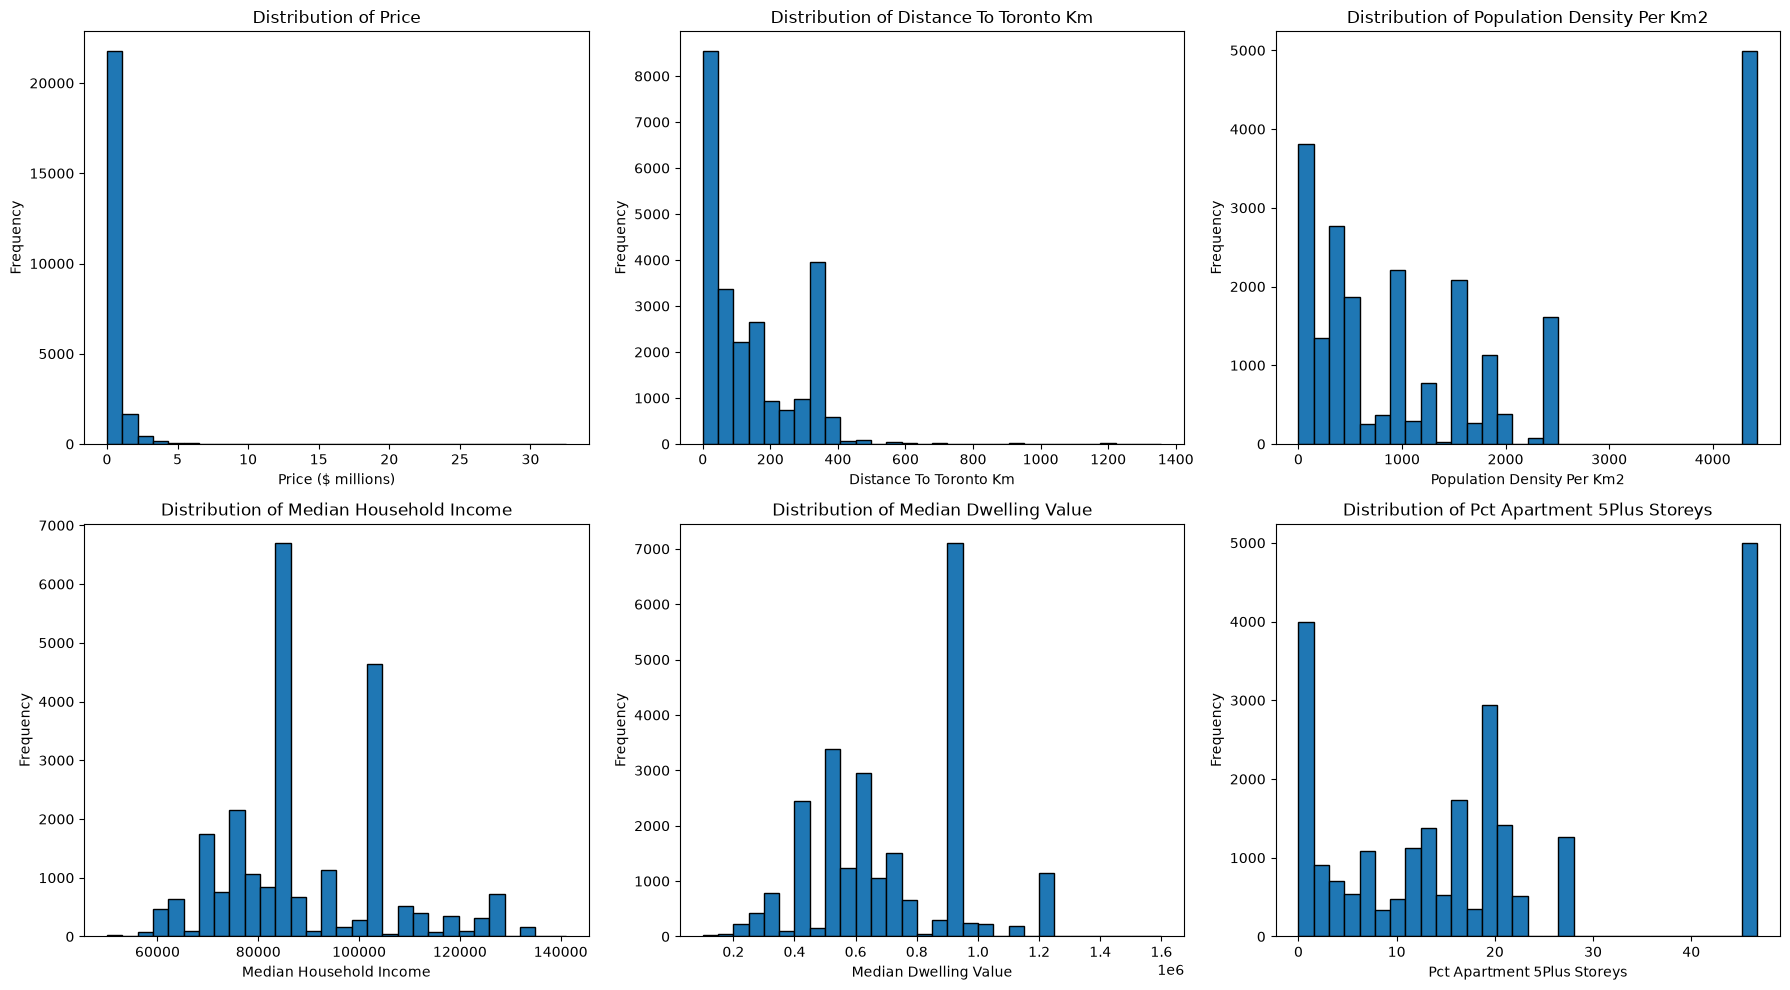

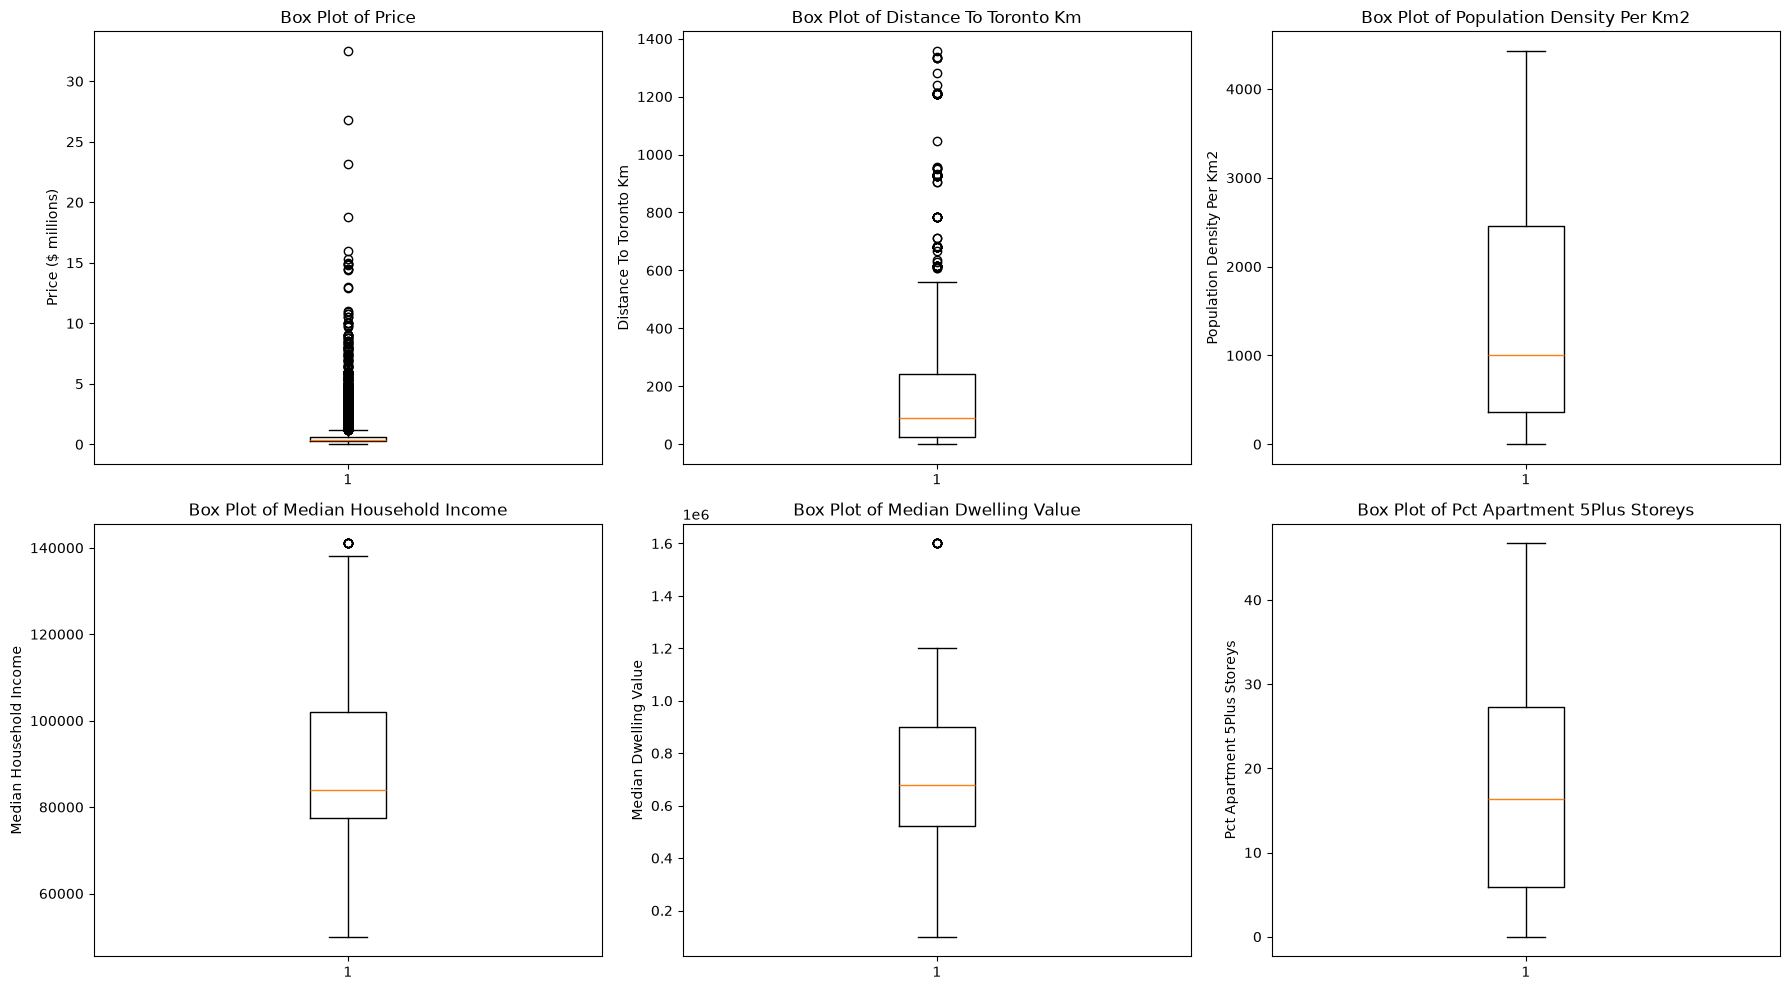

In [8]:
# Select the main numeric variables for distribution analysis

variables = [
    "price",
    "distance_to_toronto_km",
    "population_density_per_km2",
    "median_household_income",
    "median_dwelling_value",
    "pct_apartment_5plus_storeys"
]

# Create histograms
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, column in enumerate(variables):
    values = study_df[column]

    # Display property prices in millions
    if column == "price":
        values = values / 1_000_000
        xlabel = "Price ($ millions)"
    else:
        xlabel = column.replace("_", " ").title()

    axes[i].hist(values.dropna(), bins=30, edgecolor="black")
    axes[i].set_title(f"Distribution of {column.replace('_', ' ').title()}")
    axes[i].set_xlabel(xlabel)
    axes[i].set_ylabel("Frequency")

plt.tight_layout()
plt.show()


# Create box plots
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, column in enumerate(variables):
    values = study_df[column]

    # Display property prices in millions
    if column == "price":
        values = values / 1_000_000
        ylabel = "Price ($ millions)"
    else:
        ylabel = column.replace("_", " ").title()

    axes[i].boxplot(values.dropna())
    axes[i].set_title(f"Box Plot of {column.replace('_', ' ').title()}")
    axes[i].set_ylabel(ylabel)

plt.tight_layout()
plt.show()

The distribution analysis shows that property prices and population density are strongly right-skewed, with some observations having unusually high values. The box plots help identify potential outliers in the numeric variables. These patterns indicate that the data are not normally distributed and may affect linear regression results. Therefore, transformations are explored in the following sections to improve the suitability of the data for modelling.

# E. Factor variables to numeric

In [9]:
# Display original values before conversion

print("City size class - Before conversion:")
print(study_df["city_size_class"].value_counts())

print("\nCondo unit - Before conversion:")
print(study_df["is_condo_unit"].value_counts())


# Convert city_size_class into ordered numeric codes

city_size_categories = [
    "Small (<10k)",
    "Medium (10k-100k)",
    "Large (100k-500k)",
    "Very large (500k+)"
]

study_df["city_size_code"] = pd.Categorical(
    study_df["city_size_class"],
    categories=city_size_categories,
    ordered=True
).codes


# Convert is_condo_unit from Boolean to integer (0/1)

study_df["is_condo_unit"] = study_df["is_condo_unit"].astype(int)


# Display values after conversion

print("\nCity size code - After conversion:")
print(study_df["city_size_code"].value_counts().sort_index())

print("\nCondo unit - After conversion:")
print(study_df["is_condo_unit"].value_counts())

City size class - Before conversion:
city_size_class
Very large (500k+)    10224
Large (100k-500k)      7126
Medium (10k-100k)      4925
Small (<10k)           1979
Name: count, dtype: int64

Condo unit - Before conversion:
is_condo_unit
False    19385
True      4869
Name: count, dtype: int64

City size code - After conversion:
city_size_code
0     1979
1     4925
2     7126
3    10224
Name: count, dtype: int64

Condo unit - After conversion:
is_condo_unit
0    19385
1     4869
Name: count, dtype: int64


The city_size_class variable was converted into an ordered numeric variable,
with values ranging from 0 (Small) to 3 (Very large). The is_condo_unit
Boolean variable was converted into 0 and 1. Preserving the city size order
allows the model to recognize the increasing categories, while numeric
encoding makes both variables suitable for statistical analysis.

# F. Calendar dates to Julian

In [10]:
# Display original municipality inception dates

print("Original municipality inception dates:")
display(study_df[["municipality_inception_date"]].head(10))


# Convert municipality_inception_date to datetime

study_df["municipality_inception_date"] = pd.to_datetime(
    study_df["municipality_inception_date"],
    errors="coerce"
)


# Create a missing-date indicator (1 = missing, 0 = available)

study_df["inception_date_missing"] = (
    study_df["municipality_inception_date"].isna().astype(int)
)


# Convert calendar dates to Julian dates

study_df["municipality_inception_julian"] = (
    study_df["municipality_inception_date"].apply(
        lambda date: date.to_julian_date() if pd.notna(date) else float("nan")
    )
)


# Fill missing Julian dates using the median

median_julian = study_df["municipality_inception_julian"].median()

study_df["municipality_inception_julian"] = (
    study_df["municipality_inception_julian"].fillna(median_julian)
)


# Display results after conversion

print("Dates and Julian values after conversion:")
display(
    study_df[
        [
            "municipality_inception_date",
            "municipality_inception_julian",
            "inception_date_missing"
        ]
    ].head(10)
)


# Check missing values

print("Missing dates before filling:")
print(study_df["inception_date_missing"].sum())

print("\nMissing Julian values after filling:")
print(study_df["municipality_inception_julian"].isna().sum())

Original municipality inception dates:


,municipality_inception_date
0,1834-03-06
1,1846-06-09
2,1846-06-09
3,1846-06-09
4,1834-03-06
5,1834-03-06
6,1846-06-09
7,1846-06-09
8,1846-06-09
9,1827-01-01


Dates and Julian values after conversion:


,municipality_inception_date,municipality_inception_julian,inception_date_missing
0,1834-03-06,"2,390,978.5000",0
1,1846-06-09,"2,395,456.5000",0
2,1846-06-09,"2,395,456.5000",0
3,1846-06-09,"2,395,456.5000",0
4,1834-03-06,"2,390,978.5000",0
5,1834-03-06,"2,390,978.5000",0
6,1846-06-09,"2,395,456.5000",0
7,1846-06-09,"2,395,456.5000",0
8,1846-06-09,"2,395,456.5000",0
9,1827-01-01,"2,388,357.5000",0


Missing dates before filling:
2011

Missing Julian values after filling:
0


### Section F – Calendar Dates to Julian Dates

The `municipality_inception_date` column was converted into Julian dates, which represent calendar dates as continuous numerical values. This makes date information suitable for statistical and regression analysis. Missing Julian date values were replaced with the median to retain observations. A binary indicator, `inception_date_missing`, was also created to identify records that originally had missing dates.

# G. Categorical values to dummies 
**Contract with Part 2 – the check cell below must pass before you push.**

In [11]:
# Convert region categorical values into dummy variables

region_dummies = pd.get_dummies(
    study_df["region"],
    prefix="region",
    drop_first=True,
    dtype=int
)

# Remove text and identifier columns to create the modelling dataset

columns_to_drop = [
    "address",
    "area_name",
    "csd_code",
    "municipality",
    "region",
    "city_size_class",
    "municipality_inception_date"
]

model_df = study_df.drop(columns=columns_to_drop)

# Add region dummy variables

model_df = pd.concat([model_df, region_dummies], axis=1)

# Display results

print("Modelling dataset:")
display(model_df.head())

print("\nDataset shape:", model_df.shape)

print("\nData types:")
print(model_df.dtypes)

print("\nMissing values:", model_df.isna().sum().sum())

Modelling dataset:


,price,lat,lng,population_2021,population_change_pct_2016_2021,private_dwellings,population_density_per_km2,land_area_km2,average_age,median_age,pct_single_detached,pct_semi_detached,pct_row_house,pct_apartment_5plus_storeys,average_household_size,median_household_income,median_after_tax_household_income,average_household_income,pct_low_income_lim_at,pct_owner_households,pct_renter_households,average_rooms_per_dwelling,pct_built_1960_or_before,median_monthly_owner_shelter_cost,median_dwelling_value,median_monthly_rent,pct_immigrants,pct_visible_minority,pct_bachelor_or_higher,participation_rate,employment_rate,unemployment_rate,pct_commute_by_car,pct_commute_by_transit,is_condo_unit,distance_to_toronto_km,distance_to_kitchener_km,city_size_code,inception_date_missing,municipality_inception_julian,region_eastern,region_golden_horseshoe_other,region_gta_excl_toronto,region_northern,region_southwestern,region_toronto,region_waterloo_region
0,999888,43.6799,-79.5443,2794356,2.3000,1253238,"4,427.8000",631.1000,41.5000,39.6000,23.3000,6.2000,5.4000,46.7000,2.4000,84000,74000,121200,13.2000,51.9000,48.1000,4.9000,29.3000,1740,900000,"1,500.0000",46.6000,55.7000,41.1000,63.9000,55.0000,13.9000,61.0000,26.2000,0,13.2907,80.5053,3,0,"2,390,978.5000",0,0,0,0,0,1,0
1,399900,43.2500,-79.9044,569353,6.0000,233564,509.1000,"1,118.3100",41.5000,40.8000,56.2000,3.0000,12.3000,16.4000,2.5000,86000,75500,108700,10.8000,65.7000,34.3000,6.3000,32.8000,1440,700000,"1,120.0000",25.9000,25.1000,25.2000,61.9000,54.3000,12.3000,85.4000,7.4000,1,61.4826,52.5711,3,0,"2,395,456.5000",0,1,0,0,0,0,0
2,479000,43.2517,-79.9194,569353,6.0000,233564,509.1000,"1,118.3100",41.5000,40.8000,56.2000,3.0000,12.3000,16.4000,2.5000,86000,75500,108700,10.8000,65.7000,34.3000,6.3000,32.8000,1440,700000,"1,120.0000",25.9000,25.1000,25.2000,61.9000,54.3000,12.3000,85.4000,7.4000,0,62.1798,51.3974,3,0,"2,395,456.5000",0,1,0,0,0,0,0
3,285900,43.2272,-79.7674,569353,6.0000,233564,509.1000,"1,118.3100",41.5000,40.8000,56.2000,3.0000,12.3000,16.4000,2.5000,86000,75500,108700,10.8000,65.7000,34.3000,6.3000,32.8000,1440,700000,"1,120.0000",25.9000,25.1000,25.2000,61.9000,54.3000,12.3000,85.4000,7.4000,0,56.6254,63.7296,3,0,"2,395,456.5000",0,1,0,0,0,0,0
4,362000,43.6515,-79.3681,2794356,2.3000,1253238,"4,427.8000",631.1000,41.5000,39.6000,23.3000,6.2000,5.4000,46.7000,2.4000,84000,74000,121200,13.2000,51.9000,48.1000,4.9000,29.3000,1740,900000,"1,500.0000",46.6000,55.7000,41.1000,63.9000,55.0000,13.9000,61.0000,26.2000,1,1.2284,93.2980,3,0,"2,390,978.5000",0,0,0,0,0,1,0



Dataset shape: (24254, 47)

Data types:
price                                  int64
lat                                  float64
lng                                  float64
population_2021                        int64
population_change_pct_2016_2021      float64
private_dwellings                      int64
population_density_per_km2           float64
land_area_km2                        float64
average_age                          float64
median_age                           float64
pct_single_detached                  float64
pct_semi_detached                    float64
pct_row_house                        float64
pct_apartment_5plus_storeys          float64
average_household_size               float64
median_household_income                int64
median_after_tax_household_income      int64
average_household_income               int64
pct_low_income_lim_at                float64
pct_owner_households                 float64
pct_renter_households                float64
average_rooms_

### Section G – Categorical Values to Dummy Variables

The `region` categorical variable was converted into numerical dummy variables using `pd.get_dummies()`. Each region is represented by a separate binary column containing 0 or 1. The `drop_first=True` parameter removes the first category to avoid redundant information and reduce multicollinearity in the regression model.

In [12]:
# Contract check between Part 1 and Part 2 (do not edit)
required_columns = {"price", "city_size_code", "is_condo_unit", "municipality_inception_julian",
                    "inception_date_missing", "distance_to_toronto_km", "median_dwelling_value"}
assert required_columns <= set(model_df.columns), f"Missing: {required_columns - set(model_df.columns)}"
assert any(c.startswith("region_") for c in model_df.columns), "Region dummies are missing"
assert all(pd.api.types.is_numeric_dtype(t) for t in model_df.dtypes), "model_df must be fully numeric"
assert model_df.isna().sum().sum() == 0, "model_df must not contain missing values"
print(f"model_df ready: {model_df.shape[0]:,} rows x {model_df.shape[1]} numeric columns")

model_df ready: 24,254 rows x 47 numeric columns


<!-- PART 2 – OWNER: Antonio -->
# H. Box-Cox transformation (Antonio)

Prices and densities are strongly right-skewed (Section D). Linear regression works best when the dependent variable
and its residuals are roughly symmetric. The Box-Cox transformation $y^{(\lambda)} = \frac{y^\lambda - 1}{\lambda}$
($\ln y$ when $\lambda = 0$) searches for the power $\lambda$ that makes a **positive** variable closest to normal.

,Box-Cox lambda
price,0.0217
population_density_per_km2,0.2903
distance_to_toronto_km,0.2736


,skewness,shapiro_W,shapiro_p
price,9.8463,0.4958,0.0000
population_density_per_km2,0.8737,0.8026,0.0000
distance_to_toronto_km,1.3025,0.8370,0.0000
price_boxcox,0.0085,0.9838,0.0000
population_density_per_km2_boxcox,-0.1638,0.9389,0.0000
distance_to_toronto_km_boxcox,-0.1412,0.9559,0.0000


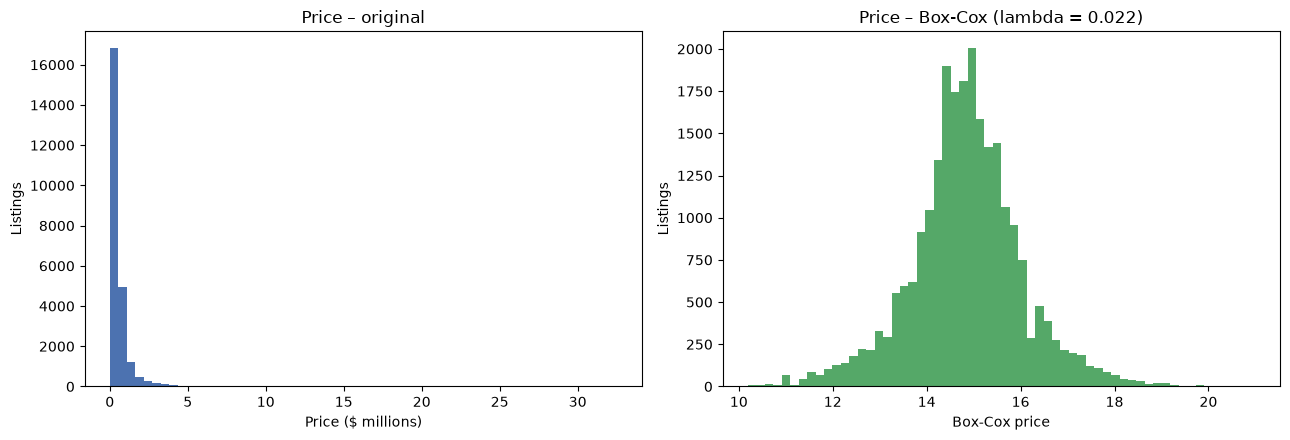

In [13]:
def skew_report(series_by_name):
    """Skewness and Shapiro-Wilk W of each series (Shapiro on a 5,000-row sample, SciPy's recommended maximum)."""
    rows = {}
    for name, values in series_by_name.items():
        sample = values.sample(min(5_000, len(values)), random_state=RANDOM_STATE)
        w_stat, p_value = shapiro(sample)
        rows[name] = {"skewness": stats.skew(values), "shapiro_W": w_stat, "shapiro_p": p_value}
    return pd.DataFrame(rows).T


def plot_before_after(before, after, title_before, title_after, xlabel_before, xlabel_after):
    """Two histograms side by side: original variable and transformed variable."""
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    axes[0].hist(before, bins=60, color="#4C72B0")
    axes[0].set(title=title_before, xlabel=xlabel_before, ylabel="Listings")
    axes[1].hist(after, bins=60, color="#55A868")
    axes[1].set(title=title_after, xlabel=xlabel_after, ylabel="Listings")
    plt.tight_layout()
    plt.show()


boxcox_columns = ["price", "population_density_per_km2", "distance_to_toronto_km"]
boxcox_lambdas = {}
for column in boxcox_columns:
    transformed, fitted_lambda = boxcox(model_df[column])   # all three columns are strictly positive
    model_df[f"{column}_boxcox"] = transformed
    boxcox_lambdas[column] = fitted_lambda

display(pd.Series(boxcox_lambdas, name="Box-Cox lambda").to_frame())
display(skew_report({**{c: model_df[c] for c in boxcox_columns},
                     **{f"{c}_boxcox": model_df[f"{c}_boxcox"] for c in boxcox_columns}}))

plot_before_after(model_df["price"] / 1e6, model_df["price_boxcox"],
                  "Price – original", f"Price – Box-Cox (lambda = {boxcox_lambdas['price']:.3f})",
                  "Price ($ millions)", "Box-Cox price")

**Box-Cox summary (≈50 words).** Box-Cox chose λ = 0.022 for price (almost a log), 0.290 for population density and 0.274 for distance to Toronto.
Price skewness fell from 9.85 to 0.01 and the Shapiro-Wilk W rose from 0.50 to 0.98, so the transformed price is close to
symmetric. Shapiro-Wilk still rejects exact normality – expected with thousands of listings – but the long right tail is gone.

# I. Tukey's Ladder of Powers (Antonio)

Tukey's ladder tries a fixed set of powers – $x^2,\ x,\ \sqrt{x},\ \ln x,\ 1/\sqrt{x},\ 1/x$ – and keeps the rung
whose result is closest to symmetric (skewness nearest 0). Unlike Box-Cox it gives an easy-to-explain transformation.
We apply it to `population_2021` and `pct_apartment_5plus_storeys` (strongly right-skewed census indicators).

,population_2021,pct_apartment_5plus_storeys
x^2,1.4192,1.2585
x (no change),1.1745,0.6854
sqrt(x),0.6726,-0.0014
log(x),-0.5720,-0.8676
-1/sqrt(x),-3.9029,-1.5456
-1/x,-9.5546,-1.9494


Rung with skewness closest to 0:
population_2021                 log(x)
pct_apartment_5plus_storeys    sqrt(x)


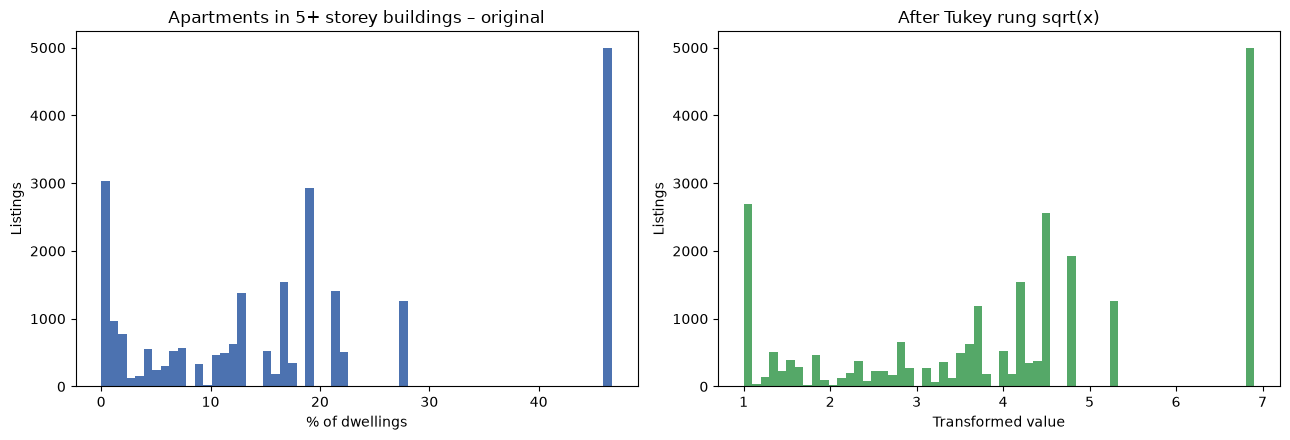

In [14]:
TUKEY_LADDER = {
    "x^2": lambda x: x ** 2,
    "x (no change)": lambda x: x,
    "sqrt(x)": np.sqrt,
    "log(x)": np.log,
    "-1/sqrt(x)": lambda x: -1 / np.sqrt(x),
    "-1/x": lambda x: -1 / x,
}


def tukey_ladder(values):
    """Skewness of the variable under each rung of Tukey's ladder (values are shifted by +1 if any are 0)."""
    shifted = values + 1 if (values <= 0).any() else values
    return pd.Series({rung: stats.skew(function(shifted)) for rung, function in TUKEY_LADDER.items()},
                     name="skewness")


tukey_columns = ["population_2021", "pct_apartment_5plus_storeys"]
ladder_table = pd.concat({column: tukey_ladder(model_df[column]) for column in tukey_columns}, axis=1)
display(ladder_table)

tukey_choice = ladder_table.abs().idxmin()
print("Rung with skewness closest to 0:")
print(tukey_choice.to_string())

for column, rung in tukey_choice.items():
    values = model_df[column] + 1 if (model_df[column] <= 0).any() else model_df[column]
    model_df[f"{column}_tukey"] = TUKEY_LADDER[rung](values)

plot_before_after(model_df["pct_apartment_5plus_storeys"], model_df["pct_apartment_5plus_storeys_tukey"],
                  "Apartments in 5+ storey buildings – original",
                  f"After Tukey rung {tukey_choice['pct_apartment_5plus_storeys']}",
                  "% of dwellings", "Transformed value")

**Tukey's Ladder summary (≈50 words).** For `population_2021` the rung with skewness closest to zero is **log(x)** (skewness 1.17 → −0.57); for
`pct_apartment_5plus_storeys` it is **√x** (0.69 → −0.001). Both new `_tukey` columns replace the originals in the MLR.
Tukey's ladder follows the same idea as Box-Cox, but with simple, explainable powers instead of an estimated λ.

# J. Train / test split and comparability (Antonio)

As in class, we split the data **80% train / 20% test** with a fixed `random_state` (so everyone gets the same split).
The model is built on the training set only; the test set measures how well it predicts listings it has never seen.
We then check that both sets are comparable: summaries, **Kolmogorov–Smirnov** for numeric variables
(H₀: same distribution) and **chi-square** for categorical variables (H₀: same proportions).

In [15]:
train_df, test_df = train_test_split(model_df, test_size=0.20, random_state=RANDOM_STATE)
print(f"Train: {train_df.shape} | Test: {test_df.shape}")

key_numeric = ["price", "price_boxcox", "distance_to_toronto_km", "population_density_per_km2",
               "median_household_income", "median_dwelling_value", "municipality_inception_julian"]
summary_comparison = pd.concat({"train mean": train_df[key_numeric].mean(), "test mean": test_df[key_numeric].mean(),
                                "train median": train_df[key_numeric].median(), "test median": test_df[key_numeric].median()},
                               axis=1)
display(summary_comparison)


def ks_comparison(train, test, columns):
    """Kolmogorov-Smirnov test for every numeric column; H0 = both samples come from the same distribution."""
    results = {c: ks_2samp(train[c], test[c]) for c in columns}
    table = pd.DataFrame({"KS statistic": {c: r.statistic for c, r in results.items()},
                          "p-value": {c: r.pvalue for c, r in results.items()}})
    table["different at 5%?"] = np.where(table["p-value"] < 0.05, "yes", "no")
    return table


binary_columns = [c for c in model_df.columns if c.startswith("region_")] + ["is_condo_unit", "inception_date_missing"]
continuous_columns = [c for c in model_df.columns if c not in binary_columns + ["city_size_code"]]
ks_table = ks_comparison(train_df, test_df, continuous_columns)
print(f"Numeric variables with a significant train/test difference: {(ks_table['p-value'] < 0.05).sum()} of {len(ks_table)}")
display(ks_table.sort_values("p-value").head(10))


def chi_square_comparison(train, test, columns):
    """Chi-square test of train vs test counts for each categorical/binary column; H0 = same proportions."""
    rows = {}
    for column in columns:
        table = pd.DataFrame({"train": train[column].value_counts(), "test": test[column].value_counts()}).fillna(0)
        chi2, p_value, dof, _ = chi2_contingency(table.T)
        rows[column] = {"chi-square": chi2, "dof": dof, "p-value": p_value}
    out = pd.DataFrame(rows).T
    out["different at 5%?"] = np.where(out["p-value"] < 0.05, "yes", "no")
    return out


region_counts = pd.DataFrame({"train": train_df[[c for c in binary_columns if c.startswith("region_")]].sum(),
                              "test": test_df[[c for c in binary_columns if c.startswith("region_")]].sum()})
display(chi_square_comparison(train_df, test_df, binary_columns + ["city_size_code"]))

Train: (19403, 52) | Test: (4851, 52)


,train mean,test mean,train median,test median
price,"589,629.0583","574,998.4113","389,700.0000","379,900.0000"
price_boxcox,14.8417,14.8238,14.8481,14.8145
distance_to_toronto_km,140.9567,142.3539,91.5107,91.8964
population_density_per_km2,"1,619.7963","1,606.4932","1,004.3000","1,004.3000"
median_household_income,"88,817.2138","88,804.4321","84,000.0000","84,000.0000"
median_dwelling_value,"694,582.7965","691,589.9814","680,000.0000","680,000.0000"
municipality_inception_julian,"2,395,729.1973","2,395,501.2223","2,390,978.5000","2,390,978.5000"


Numeric variables with a significant train/test difference: 1 of 42


,KS statistic,p-value,different at 5%?
land_area_km2,0.0219,0.0473,yes
population_density_per_km2,0.0213,0.0579,no
population_density_per_km2_boxcox,0.0213,0.0579,no
lat,0.0159,0.2801,no
lng,0.0156,0.2957,no
average_age,0.0149,0.3514,no
pct_low_income_lim_at,0.0149,0.3515,no
private_dwellings,0.0138,0.4453,no
population_change_pct_2016_2021,0.0133,0.4940,no
median_after_tax_household_income,0.0130,0.5194,no


,chi-square,dof,p-value,different at 5%?
region_eastern,0.0755,1.0000,0.7835,no
region_golden_horseshoe_other,0.0550,1.0000,0.8146,no
region_gta_excl_toronto,0.6396,1.0000,0.4239,no
region_northern,2.5260,1.0000,0.1120,no
region_southwestern,0.2621,1.0000,0.6087,no
region_toronto,0.0579,1.0000,0.8099,no
region_waterloo_region,0.9740,1.0000,0.3237,no
is_condo_unit,0.1825,1.0000,0.6692,no
inception_date_missing,1.3942,1.0000,0.2377,no
city_size_code,6.2127,3.0000,0.1017,no


**Split discussion.** The 80/20 split gives 19,403 training and 4,851 test listings. Means and medians are almost identical
(median price $389,700 train vs $379,900 test). Kolmogorov–Smirnov finds no significant difference for 41 of 42 numeric
variables; the only exception, `land_area_km2` (p = 0.047), is borderline, so we note it and keep the split. Chi-square finds
no difference in regions, condo share, missing-date flag or city size. The two sets are comparable, so the test set is a fair
check of the models.

# K. Dependent variable (Antonio)

We predict the **listing price**. Because prices are strongly right-skewed, the models use the **Box-Cox transformed
price (`price_boxcox`)** from Section H as the dependent variable. RMSE is reported on this transformed scale (the scale
the model is fitted on) and, to make it understandable, also back-transformed to dollars.

In [16]:
DEPENDENT = "price_boxcox"
PRICE_LAMBDA = boxcox_lambdas["price"]


def inverse_boxcox(values, fitted_lambda):
    """Convert Box-Cox values back to the original price scale ($)."""
    if abs(fitted_lambda) < 1e-12:
        return np.exp(values)
    return np.power(values * fitted_lambda + 1, 1 / fitted_lambda)


def evaluate_model(fitted_model, train, test, name):
    """Standard class measures for a fitted statsmodels OLS model, on train and test."""
    pred_train = fitted_model.predict(train)
    pred_test = fitted_model.predict(test)
    return pd.Series({
        "predictors": int(fitted_model.df_model),
        "F-statistic": fitted_model.fvalue,
        "Prob (F-statistic)": fitted_model.f_pvalue,
        "R-squared": fitted_model.rsquared,
        "Adj. R-squared": fitted_model.rsquared_adj,
        "AIC": fitted_model.aic,
        "RMSE train (Box-Cox)": np.sqrt(mean_squared_error(train[DEPENDENT], pred_train)),
        "RMSE test (Box-Cox)": np.sqrt(mean_squared_error(test[DEPENDENT], pred_test)),
        "Median abs. error test ($)": np.median(np.abs(test["price"] - inverse_boxcox(pred_test, PRICE_LAMBDA))),
    }, name=name)


# Correlation of every candidate predictor with the dependent variable (training set only)
candidate_predictors = [c for c in model_df.columns if c not in ("price", "price_boxcox")]
correlations = train_df[candidate_predictors].corrwith(train_df[DEPENDENT]).sort_values(key=np.abs, ascending=False)
correlations.head(12).to_frame("correlation with price_boxcox")

,correlation with price_boxcox
median_dwelling_value,0.4296
median_monthly_owner_shelter_cost,0.4153
median_monthly_rent,0.4087
average_household_income,0.3817
median_after_tax_household_income,0.3366
participation_rate,0.3358
median_household_income,0.3358
distance_to_toronto_km_boxcox,-0.3293
pct_bachelor_or_higher,0.3211
distance_to_toronto_km,-0.3194


# L. Two simple linear regression (SLR) models (Antonio)

We build one SLR for each of two **different** predictors, chosen from the correlation table above:
* **SLR 1 – `median_dwelling_value`** (census median value of dwellings in the municipality): the strongest correlation
  with the dependent variable (r = 0.43).
* **SLR 2 – `distance_to_toronto_km_boxcox`** (Box-Cox distance to downtown Toronto): a pure location measure (r = −0.33).

They capture different ideas: how valuable homes are in the community vs. how far it is from the main job market.

In [17]:
SLR_PREDICTORS = ["median_dwelling_value", "distance_to_toronto_km_boxcox"]

slr_models = {}
for predictor in SLR_PREDICTORS:
    slr_models[predictor] = smf.ols(f"{DEPENDENT} ~ {predictor}", data=train_df).fit()
    print(slr_models[predictor].summary().tables[1])
    print()

slr_comparison = pd.concat([evaluate_model(model, train_df, test_df, f"SLR: {predictor}")
                            for predictor, model in slr_models.items()], axis=1)
slr_comparison

                            coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------
Intercept                13.3198      0.024    550.075      0.000      13.272      13.367
median_dwelling_value  2.191e-06   3.31e-08     66.271      0.000    2.13e-06    2.26e-06

                                    coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------
Intercept                        15.6321      0.018    861.412      0.000      15.596      15.668
distance_to_toronto_km_boxcox    -0.0897      0.002    -48.571      0.000      -0.093      -0.086



,SLR: median_dwelling_value,SLR: distance_to_toronto_km_boxcox
predictors,1.0000,1.0000
F-statistic,"4,391.8836","2,359.1169"
Prob (F-statistic),0.0000,0.0000
R-squared,0.1846,0.1084
Adj. R-squared,0.1845,0.1084
AIC,"57,684.3432","59,417.1811"
RMSE train (Box-Cox),1.0698,1.1186
RMSE test (Box-Cox),1.0659,1.1115
Median abs. error test ($),"155,023.4417","171,344.3808"


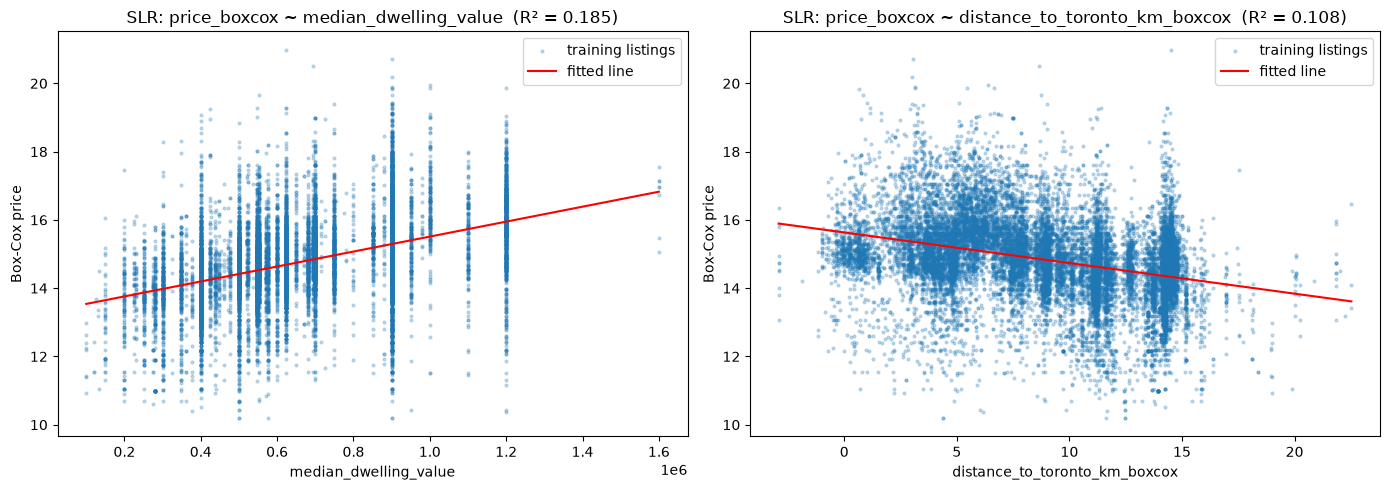

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (predictor, model) in zip(axes, slr_models.items()):
    ax.scatter(train_df[predictor], train_df[DEPENDENT], s=4, alpha=0.25, label="training listings")
    x_line = np.linspace(train_df[predictor].min(), train_df[predictor].max(), 100)
    ax.plot(x_line, model.params["Intercept"] + model.params[predictor] * x_line, color="red", label="fitted line")
    ax.set(title=f"SLR: {DEPENDENT} ~ {predictor}  (R² = {model.rsquared:.3f})", xlabel=predictor, ylabel="Box-Cox price")
    ax.legend()
plt.tight_layout()
plt.show()

**SLR comparison – which model is superior and why.** Both models are significant (Prob F-statistic ≈ 0) and both slopes have the expected sign: prices are
higher where the community's median dwelling value is higher, and lower the farther the listing is from Toronto.
**SLR 1 (median dwelling value) is superior on every measure:** higher F-statistic (4,392 vs 2,359), higher R² and adjusted R²
(0.185 vs 0.108), lower AIC, and lower RMSE on both train (1.070 vs 1.119) and test (1.066 vs 1.112). In dollars, its median
absolute error on the test set is about $155k vs $171k. Train and test RMSE are almost equal in both models, so neither
overfits. Dwelling value wins because it already summarizes many local factors (location, incomes, housing type), while
distance alone misses expensive places far from Toronto (e.g. Muskoka, The Blue Mountains). Still, one variable explains
less than a fifth of the variation in price, which motivates the multiple regression.

# M. Multiple linear regression (MLR) and variable selection (Antonio)

**Full model.** As in class, we start with **all** independent variables. Original columns that were transformed in H and I
are replaced by their transformed versions, and `pct_renter_households` is left out because owners + renters ≈ 100%
(it would be an exact duplicate of `pct_owner_households`).

**Step 2 – Backward elimination (class technique).** Remove the predictor with the highest p-value, refit, and repeat
until every remaining predictor is significant at 5%.

**Step 3 – Coefficient check.** Following the class review of coefficients, we check that the signs make sense. Where several
predictors measure the same concept (three income measures, two age measures, population and dwellings, three
labour-force rates) they compete with each other and get opposite signs – a sign of multicollinearity (the large
condition number in the summary). We keep one measure per concept and run backward elimination again.

In [19]:
replaced_by_transform = ["price", "price_boxcox", "population_density_per_km2", "distance_to_toronto_km",
                         "population_2021", "pct_apartment_5plus_storeys", "pct_renter_households"]
all_predictors = [c for c in model_df.columns if c not in replaced_by_transform]
print(f"Full model starts with {len(all_predictors)} predictors")

full_model = smf.ols(f"{DEPENDENT} ~ " + " + ".join(all_predictors), data=train_df).fit()
print(full_model.summary())

Full model starts with 45 predictors
                            OLS Regression Results                            
Dep. Variable:           price_boxcox   R-squared:                       0.266
Model:                            OLS   Adj. R-squared:                  0.264
Method:                 Least Squares   F-statistic:                     155.9
Date:                Sun, 22 Nov 2026   Prob (F-statistic):               0.00
Time:                        20:56:27   Log-Likelihood:                -27819.
No. Observations:               19403   AIC:                         5.573e+04
Df Residuals:                   19357   BIC:                         5.609e+04
Df Model:                          45                                         
Covariance Type:            nonrobust                                         
                                        coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------

In [20]:
def backward_elimination(train, predictors, alpha=0.05):
    """Drop the least significant predictor (highest p-value) one at a time until all p-values < alpha."""
    remaining = list(predictors)
    removal_log = []
    while True:
        model = smf.ols(f"{DEPENDENT} ~ " + " + ".join(remaining), data=train).fit()
        p_values = model.pvalues.drop("Intercept")
        worst = p_values.idxmax()
        if p_values[worst] < alpha:
            return model, pd.DataFrame(removal_log)
        removal_log.append({"step": len(removal_log) + 1, "removed": worst, "p-value": p_values[worst],
                            "Adj. R² before removal": model.rsquared_adj})
        remaining.remove(worst)


backward_model, removal_log = backward_elimination(train_df, all_predictors)
display(removal_log)
print(backward_model.summary())

,step,removed,p-value,Adj. R² before removal
0,1,pct_low_income_lim_at,0.9999,0.2643
1,2,land_area_km2,0.9966,0.2644
2,3,pct_apartment_5plus_storeys_tukey,0.9653,0.2644
3,4,population_density_per_km2_boxcox,0.9434,0.2644
4,5,region_waterloo_region,0.8415,0.2645
5,6,region_southwestern,0.8463,0.2645
6,7,pct_single_detached,0.7744,0.2646
7,8,region_toronto,0.7816,0.2646
8,9,city_size_code,0.7477,0.2646
9,10,pct_owner_households,0.5990,0.2647


                            OLS Regression Results                            
Dep. Variable:           price_boxcox   R-squared:                       0.265
Model:                            OLS   Adj. R-squared:                  0.264
Method:                 Least Squares   F-statistic:                     349.7
Date:                Sun, 22 Nov 2026   Prob (F-statistic):               0.00
Time:                        20:56:30   Log-Likelihood:                -27831.
No. Observations:               19403   AIC:                         5.570e+04
Df Residuals:                   19382   BIC:                         5.587e+04
Df Model:                          20                                         
Covariance Type:            nonrobust                                         
                                        coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------------------
Interc

,removed predictor,reason
0,median_household_income,income – income is already captured by dwellin...
1,average_household_income,income – duplicate of the median income measures
2,median_after_tax_household_income,income – duplicate of the other income measures
3,median_age,age – duplicate of average_age
4,private_dwellings,size – duplicate of population (and of city_si...
5,unemployment_rate,labour force – equals 100 minus employment / p...


,step,removed,p-value,Adj. R² before removal
0,1,municipality_inception_julian,0.9964,0.2633
1,2,region_waterloo_region,0.8987,0.2634
2,3,region_southwestern,0.8589,0.2634
3,4,population_density_per_km2_boxcox,0.8512,0.2634
4,5,pct_single_detached,0.8686,0.2635
5,6,land_area_km2,0.7481,0.2635
6,7,city_size_code,0.6587,0.2635
7,8,pct_owner_households,0.6394,0.2636
8,9,region_golden_horseshoe_other,0.6150,0.2636
9,10,population_change_pct_2016_2021,0.4795,0.2636


                            OLS Regression Results                            
Dep. Variable:           price_boxcox   R-squared:                       0.264
Model:                            OLS   Adj. R-squared:                  0.263
Method:                 Least Squares   F-statistic:                     434.2
Date:                Sun, 22 Nov 2026   Prob (F-statistic):               0.00
Time:                        20:56:33   Log-Likelihood:                -27848.
No. Observations:               19403   AIC:                         5.573e+04
Df Residuals:                   19386   BIC:                         5.586e+04
Df Model:                          16                                         
Covariance Type:            nonrobust                                         
                                        coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------------------
Interc

,SLR: median_dwelling_value,Full MLR,MLR after backward elimination,Final MLR (one measure per concept)
predictors,1.0000,45.0000,20.0000,16.0000
F-statistic,"4,391.8836",155.9148,349.7204,434.2474
Prob (F-statistic),0.0000,0.0000,0.0000,0.0000
R-squared,0.1846,0.2660,0.2652,0.2638
Adj. R-squared,0.1845,0.2643,0.2644,0.2632
AIC,"57,684.3432","55,730.5451","55,703.2039","55,730.4598"
RMSE train (Box-Cox),1.0698,1.0149,1.0155,1.0164
RMSE test (Box-Cox),1.0659,1.0006,1.0014,1.0021
Median abs. error test ($),"155,023.4417","133,349.9080","132,608.5445","133,496.5155"


,coefficient,p-value
is_condo_unit,-0.9136,0.0000
region_eastern,0.1843,0.0007
average_rooms_per_dwelling,0.1842,0.0000
pct_apartment_5plus_storeys_tukey,0.1100,0.0000
distance_to_toronto_km_boxcox,-0.0688,0.0000
participation_rate,0.0565,0.0000
employment_rate,-0.0368,0.0000
average_age,0.0336,0.0002
lng,-0.0312,0.0006
pct_low_income_lim_at,-0.0270,0.0001


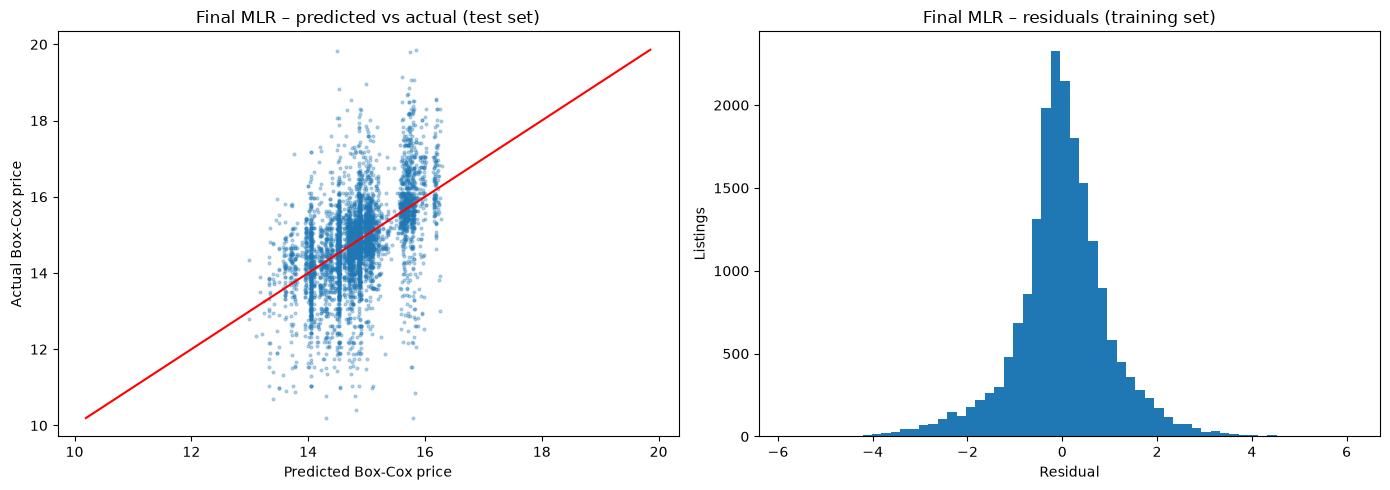

In [21]:
# Step 3: one measure per concept, then backward elimination again
DUPLICATE_CONCEPT_MEASURES = pd.DataFrame([
    ("median_household_income", "income – income is already captured by dwelling value, rent, shelter cost and low-income share"),
    ("average_household_income", "income – duplicate of the median income measures"),
    ("median_after_tax_household_income", "income – duplicate of the other income measures"),
    ("median_age", "age – duplicate of average_age"),
    ("private_dwellings", "size – duplicate of population (and of city_size_code)"),
    ("unemployment_rate", "labour force – equals 100 minus employment / participation ratio"),
], columns=["removed predictor", "reason"])
display(DUPLICATE_CONCEPT_MEASURES)

refined_predictors = [c for c in all_predictors if c not in set(DUPLICATE_CONCEPT_MEASURES["removed predictor"])]
final_model, refined_removal_log = backward_elimination(train_df, refined_predictors)
display(refined_removal_log)
print(final_model.summary())

best_slr_name = slr_comparison.loc["RMSE test (Box-Cox)"].idxmin()
model_comparison = pd.concat([
    slr_comparison[best_slr_name],
    evaluate_model(full_model, train_df, test_df, "Full MLR"),
    evaluate_model(backward_model, train_df, test_df, "MLR after backward elimination"),
    evaluate_model(final_model, train_df, test_df, "Final MLR (one measure per concept)"),
], axis=1)
display(model_comparison)

final_coefficients = pd.DataFrame({"coefficient": final_model.params, "p-value": final_model.pvalues}).drop("Intercept")
display(final_coefficients.sort_values("coefficient", key=np.abs, ascending=False))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
test_predictions = final_model.predict(test_df)
axes[0].scatter(test_predictions, test_df[DEPENDENT], s=4, alpha=0.3)
limits = [test_df[DEPENDENT].min(), test_df[DEPENDENT].max()]
axes[0].plot(limits, limits, color="red")
axes[0].set(title="Final MLR – predicted vs actual (test set)", xlabel="Predicted Box-Cox price", ylabel="Actual Box-Cox price")
axes[1].hist(final_model.resid, bins=60)
axes[1].set(title="Final MLR – residuals (training set)", xlabel="Residual", ylabel="Listings")
plt.tight_layout()
plt.show()

**MLR discussion – evidence for the final model.** 
* **Full model (45 predictors):** significant overall (Prob F ≈ 0), adjusted R² 0.264, but most predictors have p > 0.05 and
  the condition number is very large – many predictors repeat the same information.
* **Backward elimination:** 25 predictors removed one at a time; 20 remain, all with p < 0.05. Adjusted R² stays 0.264 and
  test RMSE 1.001 – removing them cost nothing.
* **Coefficient check:** that model still contained competing measures of the same concept with opposite signs (after-tax
  income + vs average income −, average age + vs median age −). Keeping one measure per concept and eliminating again gives the
  **final model: 16 predictors, all p < 0.05, F = 434, adjusted R² 0.263, RMSE train 1.016 / test 1.002** – the same accuracy
  as the 45-predictor model with about a third of the variables.
* **Signs make sense:** condo units sell for much less (−0.91 on a near-log scale, roughly 60% lower), prices fall with
  distance to Toronto and with the share of low-income households, and rise with median dwelling value, rent, owner shelter
  costs and rooms per dwelling. The pair employment rate (−) / participation rate (+) is still correlated, so we interpret it
  as one labour-market effect.
* **Versus the best SLR:** adjusted R² 0.185 → 0.263, test RMSE 1.066 → 1.002, median absolute test error ≈ $155k → $133k.
  Train ≈ test RMSE, so the model does not overfit.
* **Limitation:** R² ≈ 0.26 means most of the price variation comes from the property itself (size, bedrooms, lot), which our
  dataset does not have; census values are municipal averages shared by many listings.

**Final choice: the 16-predictor model** – simplest model with every predictor significant, sensible signs and the same
test performance as the larger models.

<!-- PART 3 – OWNER: Ved -->
# N. Summary of transformations — TODO (Ved)

**50-word summary** of every transformation performed on the data, in order, and why: cleaning and integration (C),
factor to numeric (E), Julian dates (F), dummies (G), Box-Cox (H), Tukey's Ladder (I).

# O. Model comparison table — TODO (Ved)

One table like the professor's whiteboard. Rows: Prob (F-statistic), Adj. R², significant predictors / total,
coefficient signs that make sense (yes/no), RMSE train, RMSE test. Columns: SLR 1, SLR 2, Full MLR, Final MLR.
Use the values already computed in L and M (`slr_comparison`, `model_comparison`) – do not retype numbers by hand.

# P. Conclusions and limitations — TODO (Ved)

Which model we recommend and why; what it says about Ontario prices (Toronto and Kitchener-Waterloo vs the rest);
limitations (listing prices are asking prices, census data are municipal averages, one listing date); next steps for the term project.

# Q. README and R. presentation run sheet — TODO (Ved)

* `README.md` in this folder: goal, data sources with links, how to run, contributions table (same style as Workshop B).
* Last cell of the notebook: speaker per section and seconds per section, total **7:00**
  (Asangika A–G ≈ 2:00 · Antonio H–M ≈ 3:00 · Ved N–P ≈ 2:00).